<a href="https://colab.research.google.com/github/faisu6339-glitch/RAG/blob/main/Embeddings(Part_2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install -q -U \
    langchain \
    langchain-nvidia-ai-endpoints \
    langchain-openai \
    langchain-huggingface \
    sentence-transformers \
    transformers \
    scikit-learn \
    numpy \
    matplotlib \
    faiss-cpu \
    chromadb


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.


In [2]:

from google.colab import userdata
import os

os.environ["NVIDIA_API_KEY"] = userdata.get("NVIDIA_API_KEY")

print("NVIDIA API key configured successfully!")


NVIDIA API key configured successfully!


# Program 1: Compare actual sentence embeddings

In [3]:
from math import cos
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

sentence1 = "I love learning Artificial Intelligence."

sentence2 = "I enjoy studying Machine Learning."

embedding1=model.encode(sentence1)
embedding2=model.encode(sentence2)

# Calculate similarity
similarity = cosine_similarity([embedding1], [embedding2])

print("Similarity:", similarity)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Similarity: [[0.7318301]]


**Remember**: a cosine similarity score is not a percentage of meaning or a calibrated probability. Its interpretation depends on the model and task.

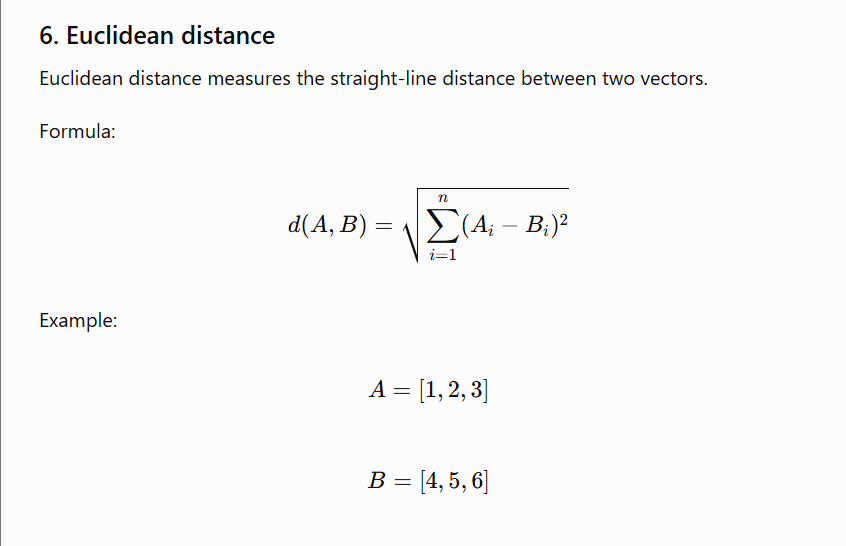

# Program 2: Calculate Euclidean distance manually

In [5]:
import numpy as np

A = np.array([1, 2, 3])

B = np.array([4, 5, 6])

difference=A-B
squared = difference ** 2
sum_squared=np.sum(squared)
distance=np.sqrt(sum_squared)

print("Vector A:",A)
print("Vector B:",B)

print("Difference:", difference)

print("Squared Difference:", squared)

print("Euclidean Distance:", distance)

Vector A: [1 2 3]
Vector B: [4 5 6]
Difference: [-3 -3 -3]
Squared Difference: [9 9 9]
Euclidean Distance: 5.196152422706632


# Program 3: Euclidean distance using Scikit-learn

In [6]:

from sklearn.metrics.pairwise import euclidean_distances
import numpy as np

A = np.array([[1, 2, 3]])

B = np.array([[4, 5, 6]])

distance = euclidean_distances(A, B)

print("Euclidean Distance:")
print(distance)


Euclidean Distance:
[[5.19615242]]


**Remember for RAG**:
- Cosine similarity: higher is generally better.
- Euclidean distance: lower is generally better.
When vectors are L2-normalized, cosine similarity and Euclidean distance produce equivalent rankings.

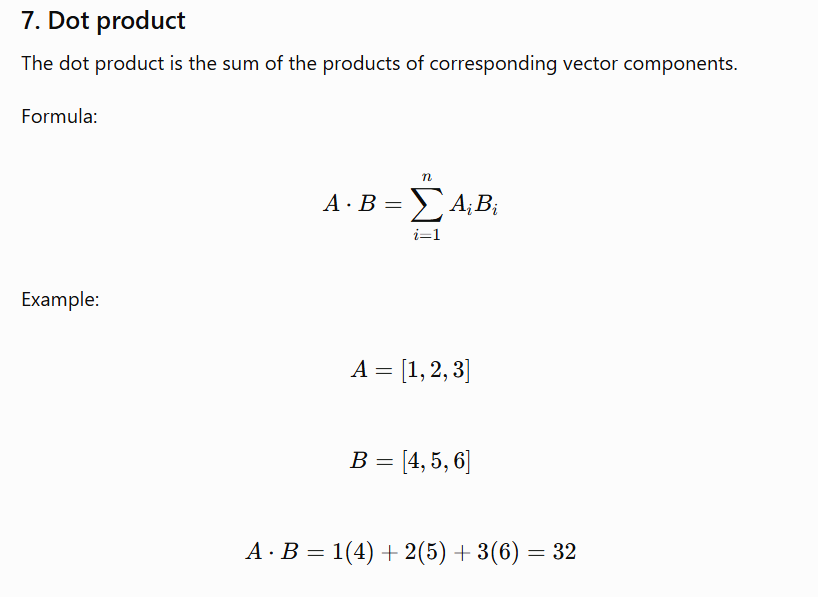

# Program 4: Calculate dot product

In [7]:

import numpy as np

A = np.array([1, 2, 3])

B = np.array([4, 5, 6])

dot = np.dot(A, B)

print("Vector A:", A)
print("Vector B:", B)

print("Dot Product:", dot)


Vector A: [1 2 3]
Vector B: [4 5 6]
Dot Product: 32


# Program 5: Dot product using actual embeddings

In [8]:

from sentence_transformers import SentenceTransformer
import numpy as np

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

texts = [
    "Machine learning is a branch of AI.",
    "Deep learning uses neural networks."
]

vectors = model.encode(texts)

dot = np.dot(vectors[0], vectors[1])

print("Dot Product:", dot)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Dot Product: 0.57952356


# 6. Similarity search
Similarity search finds the most relevant document for a given query by comparing their vectors.

Example:

User query:

**How does machine learning work?**

Documents:

Document 1: Python is a programming language.

Document 2: Machine learning allows computers to learn from data.

Document 3: Deep learning uses neural networks.


The system generates embeddings and finds the closest document to the query.

In [9]:

import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

documents = [
    "Python is a programming language.",
    "Machine learning allows computers to learn from data.",
    "Deep learning uses neural networks.",
    "The human heart pumps blood."
]

# Illustrative vectors for understanding
document_vectors = np.array([
    [0.1, 0.2, 0.3],
    [0.8, 0.7, 0.6],
    [0.7, 0.8, 0.5],
    [0.1, 0.1, 0.2]
])

query_vector = np.array([[0.75, 0.75, 0.55]])

similarities = cosine_similarity(
    query_vector,
    document_vectors
)[0]

# Sort by highest similarity
ranked_indices = np.argsort(similarities)[::-1]

for index in ranked_indices:

    print("Document:", documents[index])

    print("Similarity:", similarities[index])

    print("-" * 40)


Document: Machine learning allows computers to learn from data.
Similarity: 0.9976582555423693
----------------------------------------
Document: Deep learning uses neural networks.
Similarity: 0.9974713581770215
----------------------------------------
Document: The human heart pumps blood.
Similarity: 0.8884022797272839
----------------------------------------
Document: Python is a programming language.
Similarity: 0.8723937202332023
----------------------------------------


# Program 7: Real semantic similarity search

In [10]:

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

documents = [
    "Python is a programming language.",
    "Machine learning allows computers to learn from data.",
    "Deep learning uses neural networks.",
    "The human heart pumps blood.",
    "Artificial intelligence creates intelligent systems."
]

query = "How do computers learn from data?"

# Generate document embeddings
document_vectors = model.encode(documents)

# Generate query embedding
query_vector = model.encode([query])

# Calculate similarities
scores = cosine_similarity(
    query_vector,
    document_vectors
)[0]

# Retrieve top 3
top_indices = np.argsort(scores)[::-1][:3]

print("Query:", query)

print("\nMost Relevant Documents:\n")

for index in top_indices:

    print("Document:", documents[index])

    print("Score:", round(float(scores[index]), 4))

    print("-" * 40)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Query: How do computers learn from data?

Most Relevant Documents:

Document: Machine learning allows computers to learn from data.
Score: 0.7207
----------------------------------------
Document: Deep learning uses neural networks.
Score: 0.4467
----------------------------------------
Document: Artificial intelligence creates intelligent systems.
Score: 0.4124
----------------------------------------


# 8. Embedding dimensions
Embedding dimensions represent the number of numerical values in an embedding vector.

For example:
[0.21, 0.45, 0.67, 0.32]



This vector has four dimensions.

Different models generate different embedding dimensions.
Model	Typical dimensions
all-MiniLM-L6-v2	384
BGE-small-en-v1.5	384
BGE-base-en-v1.5	768
BGE-large-en-v1.5	1024
OpenAI text-embedding-3-small	1536 by default
NVIDIA nv-embedqa-e5-v5	1024

Sources:
OpenAI API+2

#Program 8: Check embedding dimensions

In [11]:

from sentence_transformers import SentenceTransformer

models = [
    "sentence-transformers/all-MiniLM-L6-v2",
    "BAAI/bge-small-en-v1.5",
    "BAAI/bge-base-en-v1.5"
]

text = "Artificial Intelligence is interesting."

for model_name in models:

    model = SentenceTransformer(model_name)

    embedding = model.encode(text)

    print("\nModel:", model_name)

    print("Dimensions:", len(embedding))


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Model: sentence-transformers/all-MiniLM-L6-v2
Dimensions: 384


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

... (20 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


Model: BAAI/bge-base-en-v1.5
Dimensions: 768


# 9. Embedding models

In [12]:

from langchain_nvidia_ai_endpoints import NVIDIAEmbeddings

model = NVIDIAEmbeddings(
    model="nvidia/nv-embedqa-e5-v5"
)

documents = [
    "Machine learning is a subset of AI.",
    "Deep learning uses neural networks.",
    "Python is a programming language."
]

vectors = model.embed_documents(documents)

print("Number of embeddings:", len(vectors))

for i, vector in enumerate(vectors):

    print("\nDocument:", documents[i])

    print("Dimensions:", len(vector))

    print("First 5 values:", vector[:5])


Exception: [410] Gone
The model 'nvidia/nv-embedqa-e5-v5' has reached its end of life on 2026-08-25T09:00:00Z and is no longer available.

In [13]:

!pip install -q -U openai


In [14]:

from google.colab import userdata
from openai import OpenAI

client = OpenAI(
    api_key=userdata.get("OPENAI_API_KEY")
)

text = "Artificial Intelligence is transforming technology."

response = client.embeddings.create(
    model="text-embedding-3-small",
    input=text
)

vector = response.data[0].embedding

print("Embedding:", vector[:10])

print("Dimensions:", len(vector))

print("Tokens Used:", response.usage.total_tokens)


SecretNotFoundError: Secret OPENAI_API_KEY does not exist.